# Prompt

> Begin writing a new python notebook using PyTorch that will train a basic CNN For the AD vs NC classifier using the dataloader from dataset.py.
>
> Create this in a new notebook titled 'basic_cnn_ad_vs_nc_classifier'.
>
> It should be a simple 'shallow' model that can train epochs relatively quickly. Have the training cell save model weights to an output/basic_cnn folder and then in a final cell print test set accuracy, examples of correct, false positive, and false negatives.
>
> During training at the end of each epoch print the training accuracy, and validation accuracy.

# Basic CNN: AD vs NC

This notebook trains a small subject-level classifier. A shallow 2D CNN encodes a small, evenly spaced selection of MRI slices from each subject, and the slice features are averaged before classification. Limiting both the image size and number of slices keeps epochs relatively quick.

In [1]:
import sys
from pathlib import Path

import torch
from torch import nn

# Support launching Jupyter from either this folder or the repository root.
dataset_dir = Path.cwd()
if not (dataset_dir / "dataset.py").is_file():
    candidate = Path.cwd() / "recognition" / "s4743113"
    if (candidate / "dataset.py").is_file():
        dataset_dir = candidate
    else:
        raise FileNotFoundError("Could not locate recognition/s4743113/dataset.py")
sys.path.insert(0, str(dataset_dir.resolve()))

from dataset import create_adni_dataloaders, set_seed

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}")
print(f"Device: {DEVICE}")

PyTorch 2.13.0+cu130
Device: cpu


In [2]:
SEED = 42
BATCH_SIZE = 4
IMAGE_SIZE = (96, 96)
MAX_SLICES_PER_SUBJECT = 12
EPOCHS = 100
TARGET_VALIDATION_ACCURACY = 0.80
LEARNING_RATE = 1e-3
DATA_DIR = dataset_dir / "ADNI" / "AD_NC"

set_seed(SEED)
train_loader, validation_loader, test_loader = create_adni_dataloaders(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    validation_fraction=0.2,
    seed=SEED,
    image_size=IMAGE_SIZE,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

class_to_idx = train_loader.dataset.dataset.class_to_idx
idx_to_class = {index: name for name, index in class_to_idx.items()}
normalised_classes = {name.casefold(): index for name, index in class_to_idx.items()}
if (
    len(class_to_idx) != 2
    or "ad" not in normalised_classes
    or "nc" not in normalised_classes
):
    raise ValueError(
        f"Expected non-empty AD and NC folders in both dataset splits, "
        f"but the training data contains {class_to_idx}."
    )
AD_INDEX = normalised_classes["ad"]
NC_INDEX = normalised_classes["nc"]

print(f"Dataset: {DATA_DIR.resolve()}")
print(f"Training subjects:   {len(train_loader.dataset)}")
print(f"Validation subjects: {len(validation_loader.dataset)}")
print(f"Test subjects:       {len(test_loader.dataset)}")
print(f"Classes: {class_to_idx}")

Dataset: /home/ron/uni/comp3710/PatternAnalysis-2026/recognition/s4743113/ADNI/AD_NC
Training subjects:   861
Validation subjects: 215
Test subjects:       450
Classes: {'AD': 0, 'NC': 1}


## Model

Each loader batch has shape `[subjects, slices, channels, height, width]`. The helper below uses the supplied slice mask to choose up to 12 evenly spaced real slices per subject. The CNN processes those slices, then masked subject-level aggregation is achieved by averaging only the selected features from each subject.

In [3]:
def pack_evenly_spaced_slices(images, slice_mask, max_slices):
    """Return selected slices as one tensor plus each subject's slice count."""
    packed_slices = []
    slice_counts = []

    for subject_images, subject_mask in zip(images, slice_mask):
        valid_images = subject_images[subject_mask]
        count = min(len(valid_images), max_slices)
        if count == 0:
            raise ValueError("A subject has no valid slices")

        indices = torch.linspace(0, len(valid_images) - 1, steps=count).round().long()
        packed_slices.append(valid_images[indices])
        slice_counts.append(count)

    return torch.cat(packed_slices, dim=0), slice_counts


class ShallowSubjectCNN(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.slice_encoder = nn.Sequential(
            nn.Conv2d(3, 12, kernel_size=5, stride=2, padding=2),
            nn.BatchNorm2d(12),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(12, 24, kernel_size=3, padding=1),
            nn.BatchNorm2d(24),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(24, 48, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.25),
            nn.Linear(48, num_classes),
        )

    def forward(self, packed_slices, slice_counts):
        slice_features = self.slice_encoder(packed_slices)
        subject_features = torch.stack(
            [features.mean(dim=0) for features in torch.split(slice_features, slice_counts)]
        )
        return self.classifier(subject_features)


model = ShallowSubjectCNN(num_classes=len(class_to_idx)).to(DEVICE)
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(model)
print(f"Trainable parameters: {trainable_parameters:,}")

ShallowSubjectCNN(
  (slice_encoder): Sequential(
    (0): Conv2d(3, 12, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (1): BatchNorm2d(12, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(12, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): AdaptiveAvgPool2d(output_size=1)
    (11): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Sequential(
    (0): Dropout(p=0.25, inplace=False)
    (1): Linear(in_features=48, out_features=2, bias=True)
  )
)
Trainable parameters: 14,114


In [4]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)
    total_loss = 0.0
    total_correct = 0
    total_subjects = 0

    for batch in loader:
        packed_slices, slice_counts = pack_evenly_spaced_slices(
            batch["images"], batch["slice_mask"], MAX_SLICES_PER_SUBJECT
        )
        packed_slices = packed_slices.to(DEVICE, non_blocking=True)
        labels = batch["labels"].to(DEVICE, non_blocking=True)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(packed_slices, slice_counts)
            loss = criterion(logits, labels)
            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_subjects += batch_size

    return total_loss / total_subjects, total_correct / total_subjects

## Train

The best validation weights and the weights from the final epoch are saved under `output/basic_cnn`. Each epoch reports both training and validation accuracy. Training stops early as soon as validation accuracy reaches 80%, with a maximum of 100 epochs.

In [5]:
OUTPUT_DIR = dataset_dir / "output" / "basic_cnn"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_WEIGHTS_PATH = OUTPUT_DIR / "best_model_weights.pt"
LAST_WEIGHTS_PATH = OUTPUT_DIR / "last_model_weights.pt"

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
best_validation_accuracy = -1.0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = run_epoch(model, train_loader, criterion, optimizer)
    validation_loss, validation_accuracy = run_epoch(
        model, validation_loader, criterion
    )

    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy
        torch.save(model.state_dict(), BEST_WEIGHTS_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
        f"validation loss {validation_loss:.4f}, accuracy {validation_accuracy:.2%}"
    )

    if validation_accuracy >= TARGET_VALIDATION_ACCURACY:
        print(
            f"Early stopping: validation accuracy reached "
            f"{validation_accuracy:.2%} (target {TARGET_VALIDATION_ACCURACY:.0%})."
        )
        break

torch.save(model.state_dict(), LAST_WEIGHTS_PATH)
print(f"Best weights saved to: {BEST_WEIGHTS_PATH}")
print(f"Final weights saved to: {LAST_WEIGHTS_PATH}")

Epoch 01/100 | train loss 0.7014, accuracy 47.62% | validation loss 0.6872, accuracy 51.63%
Epoch 02/100 | train loss 0.6946, accuracy 50.17% | validation loss 0.6939, accuracy 46.98%
Epoch 03/100 | train loss 0.6945, accuracy 50.06% | validation loss 0.6923, accuracy 62.33%
Epoch 04/100 | train loss 0.6950, accuracy 51.10% | validation loss 0.6951, accuracy 46.98%
Epoch 05/100 | train loss 0.6941, accuracy 49.48% | validation loss 0.6888, accuracy 52.56%
Epoch 06/100 | train loss 0.6923, accuracy 50.06% | validation loss 0.6948, accuracy 46.98%
Epoch 07/100 | train loss 0.6937, accuracy 50.99% | validation loss 0.6900, accuracy 52.56%
Epoch 08/100 | train loss 0.6925, accuracy 50.06% | validation loss 0.6876, accuracy 52.09%
Epoch 09/100 | train loss 0.6884, accuracy 54.59% | validation loss 0.6972, accuracy 46.98%
Epoch 10/100 | train loss 0.6922, accuracy 51.80% | validation loss 0.6851, accuracy 52.56%
Epoch 11/100 | train loss 0.6909, accuracy 51.57% | validation loss 0.6936, accu

## Test results

AD is treated as the positive class: a false positive is NC predicted as AD, and a false negative is AD predicted as NC. The confidence shown is the model's estimated probability of AD.

In [6]:
model.load_state_dict(torch.load(BEST_WEIGHTS_PATH, map_location=DEVICE, weights_only=True))
model.eval()
results = []

with torch.inference_mode():
    for batch in test_loader:
        packed_slices, slice_counts = pack_evenly_spaced_slices(
            batch["images"], batch["slice_mask"], MAX_SLICES_PER_SUBJECT
        )
        logits = model(packed_slices.to(DEVICE, non_blocking=True), slice_counts)
        probabilities = logits.softmax(dim=1).cpu()
        predictions = probabilities.argmax(dim=1)

        for sample_id, target, prediction, probability in zip(
            batch["sample_ids"], batch["labels"], predictions, probabilities
        ):
            results.append(
                {
                    "sample_id": sample_id,
                    "target": target.item(),
                    "prediction": prediction.item(),
                    "ad_probability": probability[AD_INDEX].item(),
                }
            )

correct = [result for result in results if result["prediction"] == result["target"]]
false_positives = [
    result
    for result in results
    if result["prediction"] == AD_INDEX and result["target"] == NC_INDEX
]
false_negatives = [
    result
    for result in results
    if result["prediction"] == NC_INDEX and result["target"] == AD_INDEX
]
test_accuracy = len(correct) / len(results)

def print_examples(title, examples, limit=5):
    print(f"\n{title} ({len(examples)} total):")
    if not examples:
        print("  None")
        return
    for result in examples[:limit]:
        print(
            f"  {result['sample_id']}: "
            f"actual={idx_to_class[result['target']]}, "
            f"predicted={idx_to_class[result['prediction']]}, "
            f"P(AD)={result['ad_probability']:.3f}"
        )

print(f"Test accuracy: {test_accuracy:.2%} ({len(correct)}/{len(results)})")
print_examples("Correct examples", correct)
print_examples("False positives (NC predicted as AD)", false_positives)
print_examples("False negatives (AD predicted as NC)", false_negatives)

Test accuracy: 71.78% (323/450)

Correct examples (323 total):
  1003730: actual=AD, predicted=AD, P(AD)=0.586
  1020512: actual=AD, predicted=AD, P(AD)=0.567
  1038941: actual=AD, predicted=AD, P(AD)=0.824
  1039632: actual=AD, predicted=AD, P(AD)=0.639
  1061746: actual=AD, predicted=AD, P(AD)=0.653

False positives (NC predicted as AD) (52 total):
  1186516: actual=NC, predicted=AD, P(AD)=0.645
  1212969: actual=NC, predicted=AD, P(AD)=0.723
  1214021: actual=NC, predicted=AD, P(AD)=0.764
  1215774: actual=NC, predicted=AD, P(AD)=0.768
  1219675: actual=NC, predicted=AD, P(AD)=0.739

False negatives (AD predicted as NC) (75 total):
  1004740: actual=AD, predicted=NC, P(AD)=0.214
  1005735: actual=AD, predicted=NC, P(AD)=0.086
  1011824: actual=AD, predicted=NC, P(AD)=0.156
  1017725: actual=AD, predicted=NC, P(AD)=0.191
  1029798: actual=AD, predicted=NC, P(AD)=0.396


### Test confusion grid

AD is the positive class.

| Actual / Predicted | NC | AD |
|---|---:|---:|
| **NC** | **TN: 175** | **FP: 52** |
| **AD** | **FN: 75** | **TP: 148** |

Accuracy:  71.78%
Precision: 74.00%
Recall:    66.37%


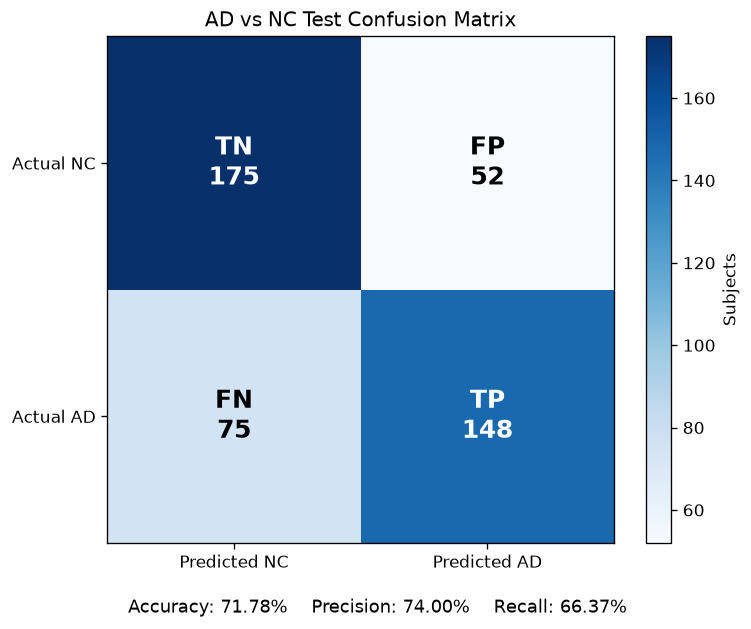

In [7]:
from IPython.display import Markdown, display

true_positives = sum(
    result["prediction"] == AD_INDEX and result["target"] == AD_INDEX
    for result in results
)
false_positives_count = sum(
    result["prediction"] == AD_INDEX and result["target"] == NC_INDEX
    for result in results
)
false_negatives_count = sum(
    result["prediction"] == NC_INDEX and result["target"] == AD_INDEX
    for result in results
)
true_negatives = sum(
    result["prediction"] == NC_INDEX and result["target"] == NC_INDEX
    for result in results
)

accuracy = (true_positives + true_negatives) / len(results)
precision = true_positives / (true_positives + false_positives_count)
recall = true_positives / (true_positives + false_negatives_count)

confusion_grid = f"""
### Test confusion grid

AD is the positive class.

| Actual / Predicted | NC | AD |
|---|---:|---:|
| **NC** | **TN: {true_negatives}** | **FP: {false_positives_count}** |
| **AD** | **FN: {false_negatives_count}** | **TP: {true_positives}** |
"""
display(Markdown(confusion_grid))
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")

import matplotlib.pyplot as plt

confusion_matrix = [[true_negatives, false_positives_count], [false_negatives_count, true_positives]]
cell_labels = [
    [f"TN\n{true_negatives}", f"FP\n{false_positives_count}"],
    [f"FN\n{false_negatives_count}", f"TP\n{true_positives}"],
]

figure, axis = plt.subplots(figsize=(6.4, 5.2))
heatmap = axis.imshow(confusion_matrix, cmap="Blues")
axis.set_xticks([0, 1], labels=["Predicted NC", "Predicted AD"])
axis.set_yticks([0, 1], labels=["Actual NC", "Actual AD"])
axis.set_title("AD vs NC Test Confusion Matrix")

threshold = max(max(row) for row in confusion_matrix) / 2
for row in range(2):
    for column in range(2):
        axis.text(
            column,
            row,
            cell_labels[row][column],
            ha="center",
            va="center",
            fontsize=15,
            fontweight="bold",
            color="white" if confusion_matrix[row][column] > threshold else "black",
        )

figure.colorbar(heatmap, ax=axis, label="Subjects")
figure.text(
    0.5,
    0.01,
    f"Accuracy: {accuracy:.2%}    Precision: {precision:.2%}    Recall: {recall:.2%}",
    ha="center",
    fontsize=11,
)
figure.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()